In [1]:
# importing needed packages
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# read in the cleaned CSV with data from central valley stations
path = 'D:/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
if os.path.exists(path):
    CV_rows = pd.read_csv(path, low_memory = False)
else:
    path = '/Volumes/disk1/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
    CV_rows = pd.read_csv(path, low_memory = False)

print(CV_rows)

           STATION_ID         STATION                 DATE  year  month  day  \
0         USW00023155  BAKERSFIELD AP  1928-01-01 02:00:00  1928      1    1   
1         USW00023155  BAKERSFIELD AP  1928-01-01 05:00:00  1928      1    1   
2         USW00023155  BAKERSFIELD AP  1928-01-01 08:00:00  1928      1    1   
3         USW00023155  BAKERSFIELD AP  1928-01-01 09:00:00  1928      1    1   
4         USW00023155  BAKERSFIELD AP  1928-01-01 11:00:00  1928      1    1   
...               ...             ...                  ...   ...    ...  ...   
10131269  USW00023202  TRAVIS FLD AFB  2026-09-28 02:55:00  2026      9   28   
10131270  USW00023202  TRAVIS FLD AFB  2026-09-28 03:55:00  2026      9   28   
10131271  USW00023202  TRAVIS FLD AFB  2026-09-28 04:55:00  2026      9   28   
10131272  USW00023202  TRAVIS FLD AFB  2026-09-28 05:55:00  2026      9   28   
10131273  USW00023202  TRAVIS FLD AFB  2026-09-28 06:55:00  2026      9   28   

          hour  minute  LATITUDE  LONGI

In [3]:
#Remove duplicate hours for each station
CV_rows = CV_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])

print(CV_rows.shape)

(8172697, 16)


In [4]:
# Exclude days from April through October (months 4-10) in CV_rows
CV_rows = CV_rows[~CV_rows['month'].isin([4, 5, 6, 7, 8, 9, 10])]

print("CV_rows after removing April-October:", CV_rows.shape)

CV_rows after removing April-October: (8172697, 16)


In [14]:
# Keep only rows with defined nonzero precipitation values
CV_precip_rows = CV_rows[(CV_rows['HourlyPrecipitation'].notna()) & (CV_rows['HourlyPrecipitation'] >= 0.03)]

print("CV_precip_rows after keeping nonzero precipitation values:", CV_precip_rows.shape)

CV_precip_rows after keeping nonzero precipitation values: (85360, 16)


In [15]:
CV_vis_rows = CV_rows[CV_rows['HourlyVisibility'].notna()]

print("CV_vis_rows after keeping defined visibility values:", CV_vis_rows.shape)

CV_vis_rows after keeping defined visibility values: (7991469, 16)


In [16]:
CV_precip_rows


,STATION_ID,STATION,DATE,year,month,day,hour,minute,LATITUDE,LONGITUDE,HourlyDryBulbTemperature,HourlyDewPointTemperature,HourlyWindDirection,HourlyWindSpeed,HourlyPrecipitation,HourlyVisibility
167264,USW00023155,BAKERSFIELD AP,1948-10-11 15:00:00,1948,10,11,15,0,35.4342,-119.0553,17.2,14.4,23.0,5.2,3.6,16.0
168536,USW00023155,BAKERSFIELD AP,1948-12-03 15:00:00,1948,12,3,15,0,35.4342,-119.0553,6.1,4.4,360.0,8.2,1.5,9.6
168537,USW00023155,BAKERSFIELD AP,1948-12-03 16:00:00,1948,12,3,16,0,35.4342,-119.0553,6.1,3.9,90.0,3.6,0.8,16.0
168542,USW00023155,BAKERSFIELD AP,1948-12-03 21:00:00,1948,12,3,21,0,35.4342,-119.0553,5.6,4.4,225.0,3.6,0.3,16.0
168599,USW00023155,BAKERSFIELD AP,1948-12-06 06:00:00,1948,12,6,6,0,35.4342,-119.0553,6.7,6.1,315.0,3.6,0.5,4.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10127672,USW00023202,TRAVIS FLD AFB,2026-05-04 21:55:00,2026,5,4,21,55,38.2667,-121.9333,12.0,10.6,200.0,3.1,1.8,16.0
10127673,USW00023202,TRAVIS FLD AFB,2026-05-04 22:55:00,2026,5,4,22,55,38.2667,-121.9333,11.9,10.6,220.0,2.6,1.5,16.0
10127679,USW00023202,TRAVIS FLD AFB,2026-05-05 01:55:00,2026,5,5,1,55,38.2667,-121.9333,11.9,10.6,210.0,5.1,0.8,16.0
10128243,USW00023202,TRAVIS FLD AFB,2026-05-28 04:55:00,2026,5,28,4,55,38.2667,-121.9333,12.6,10.7,280.0,2.6,0.5,16.0


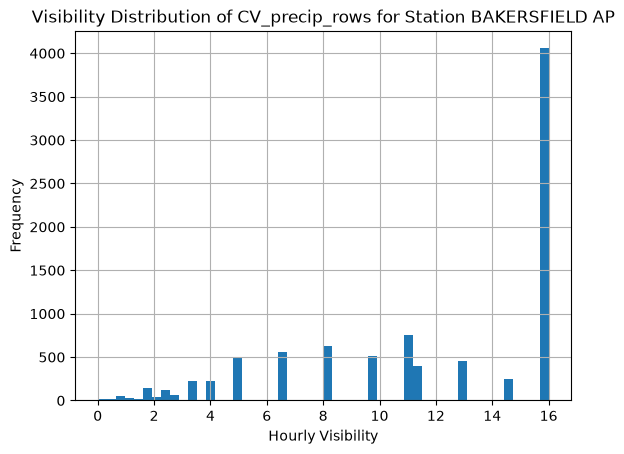

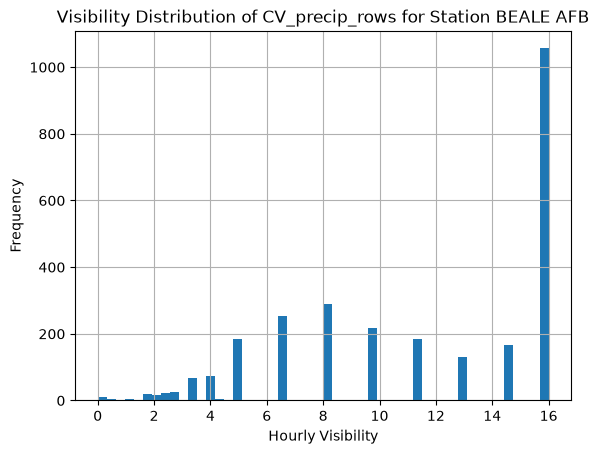

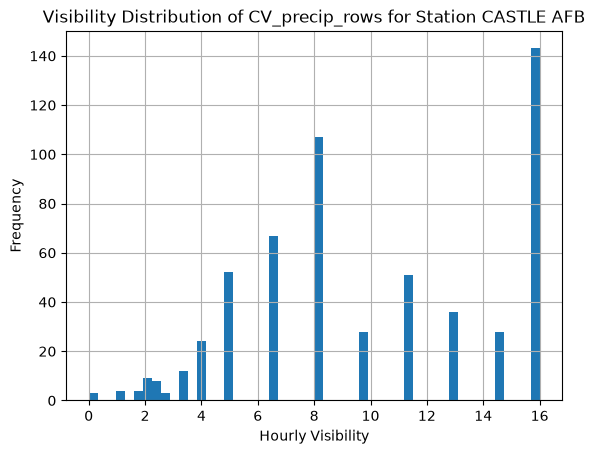

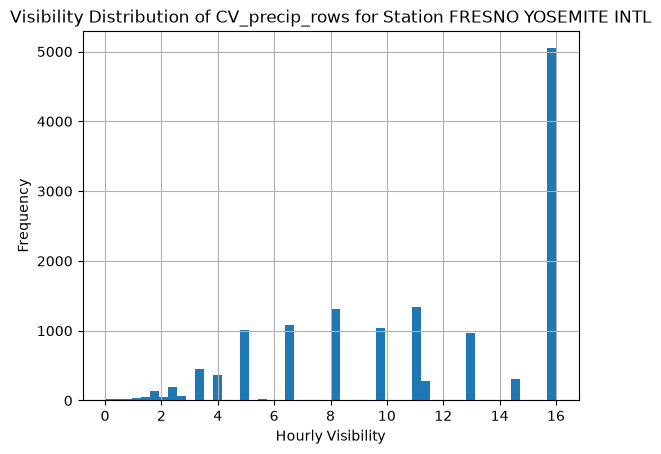

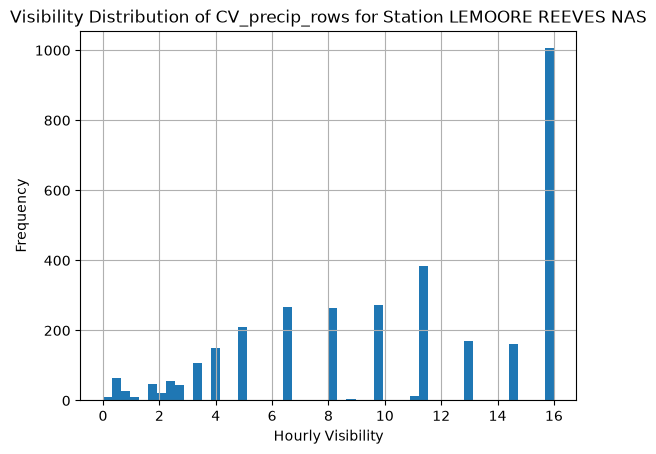

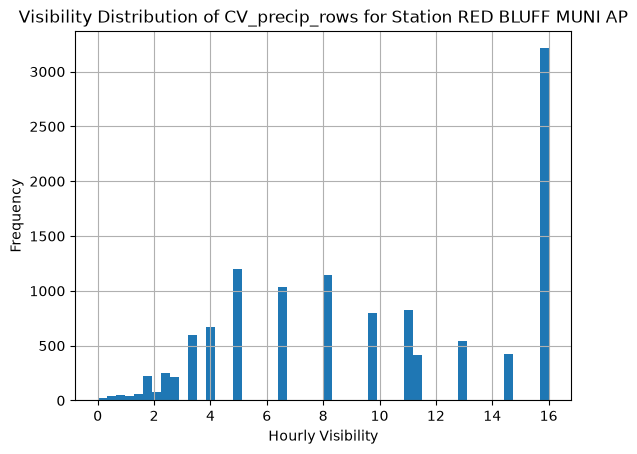

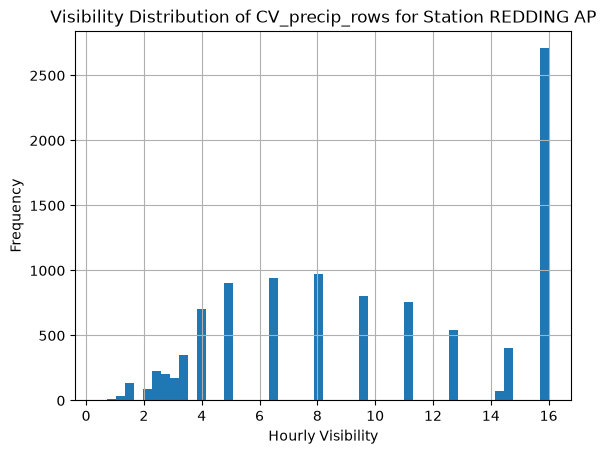

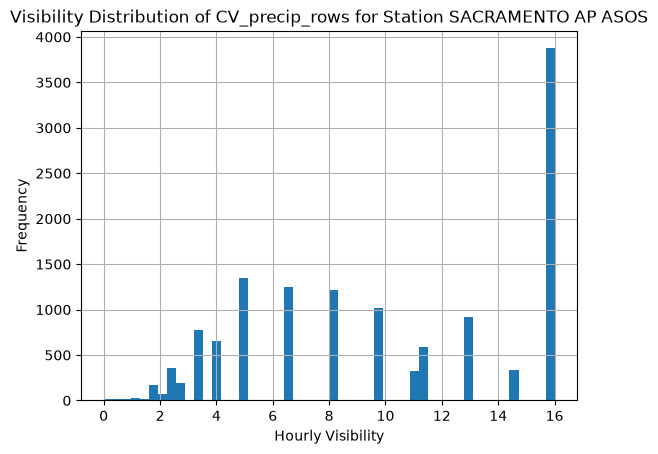

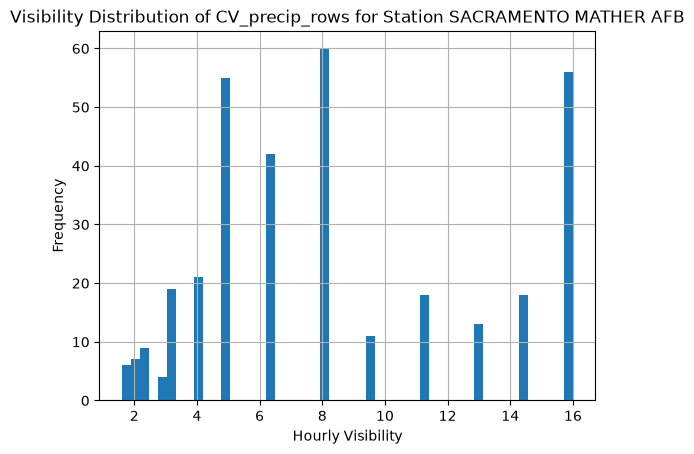

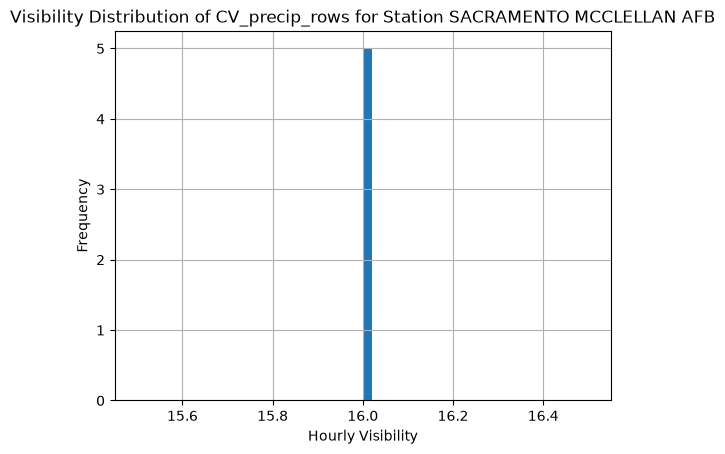

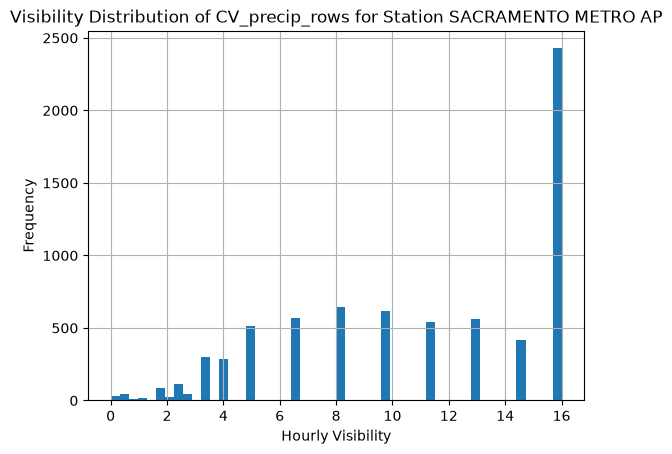

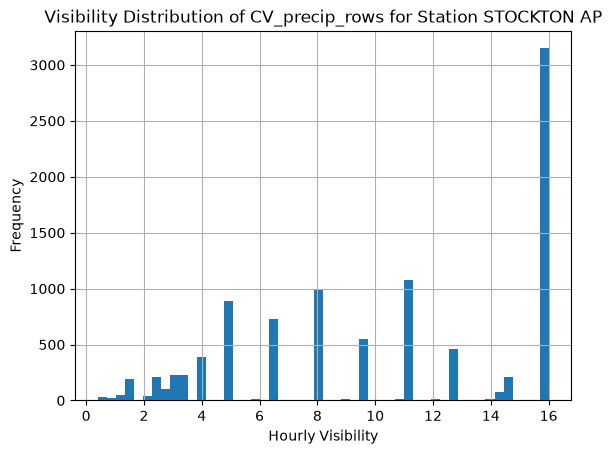

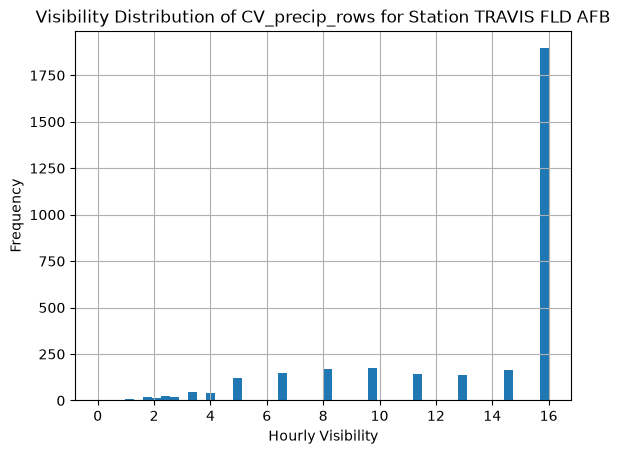

In [17]:
#Show visibility distribution of CV_precip_rows by individual station
for station in CV_precip_rows['STATION'].unique():
    CV_precip_rows[CV_precip_rows['STATION'] == station]['HourlyVisibility'].hist(bins=50)
    plt.xlabel('Hourly Visibility')
    plt.ylabel('Frequency')
    plt.title(f'Visibility Distribution of CV_precip_rows for Station {station}')
    plt.show()

CV_precip_lowvis: (601, 16)


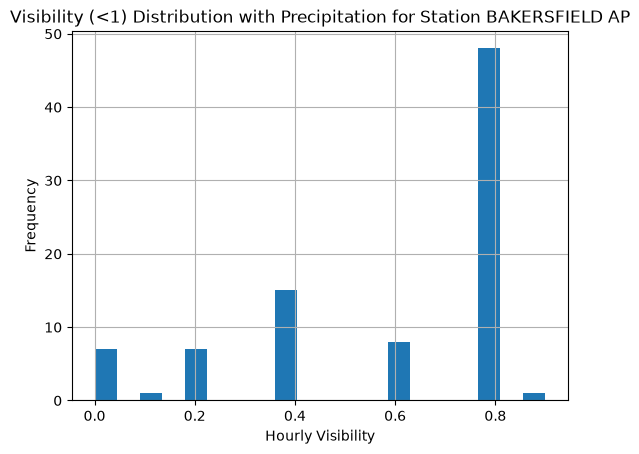

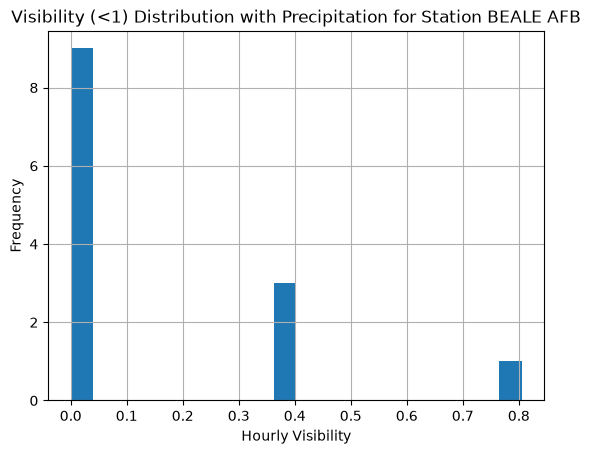

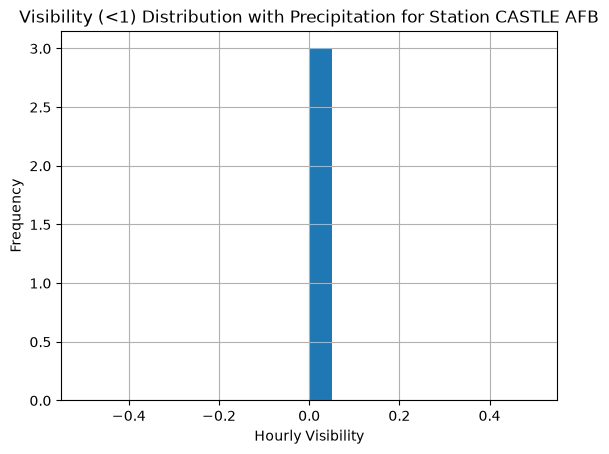

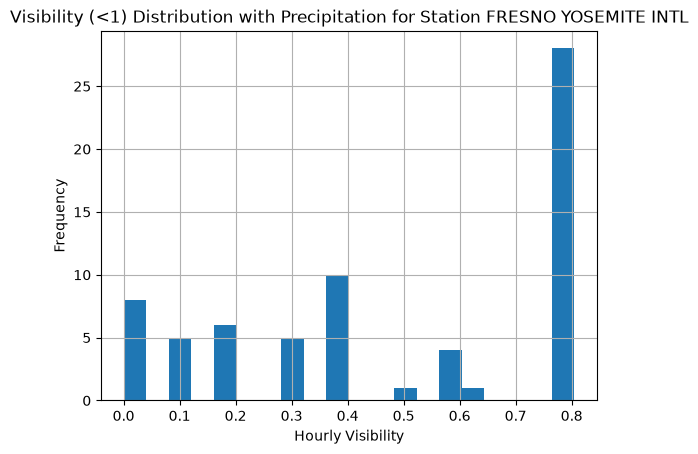

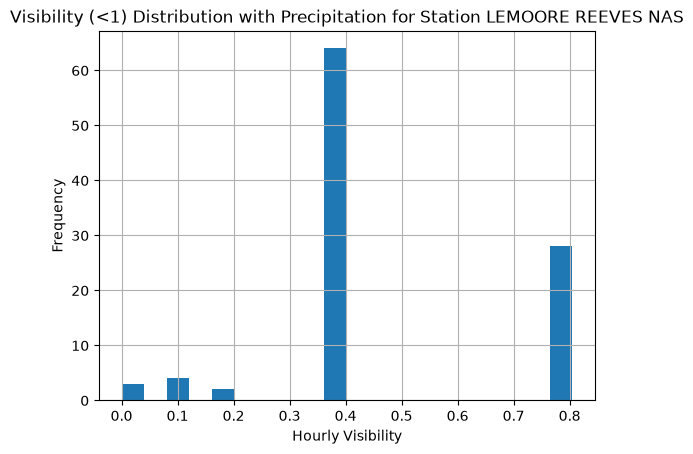

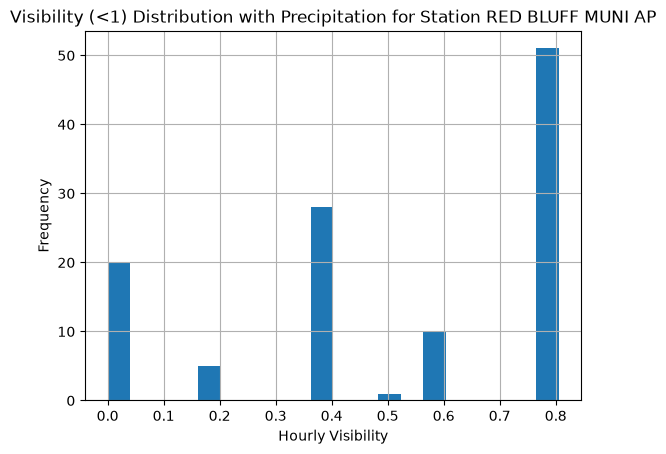

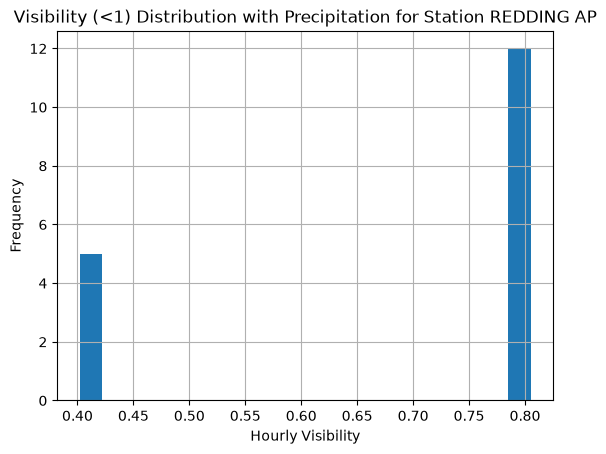

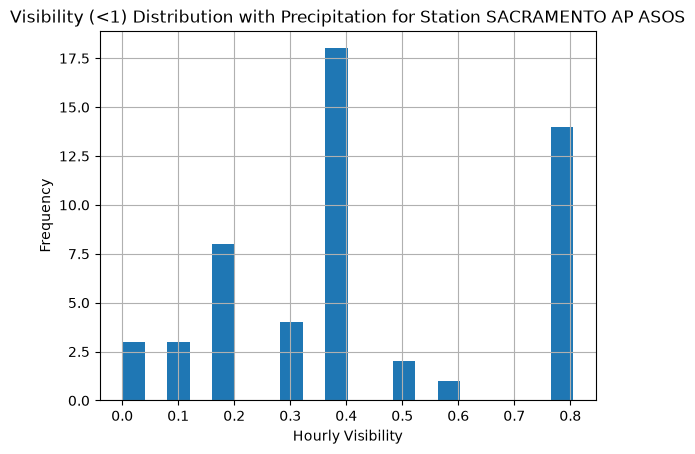

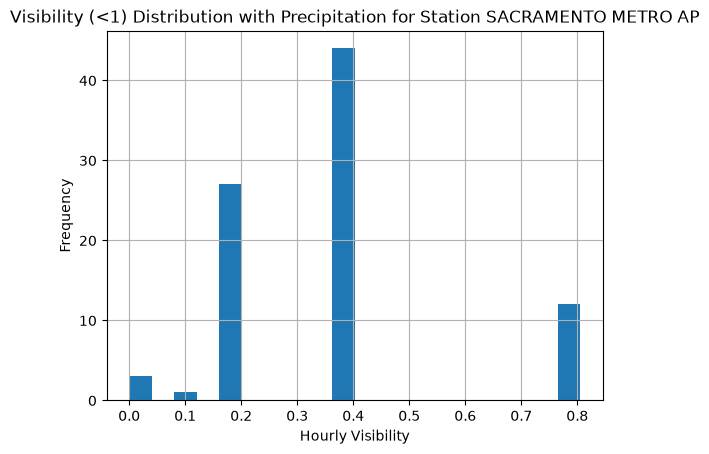

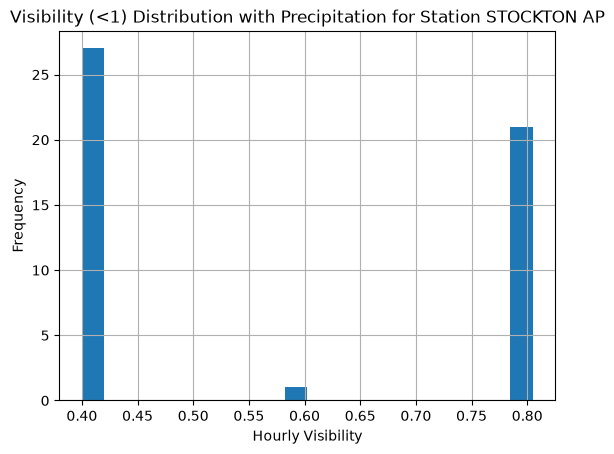

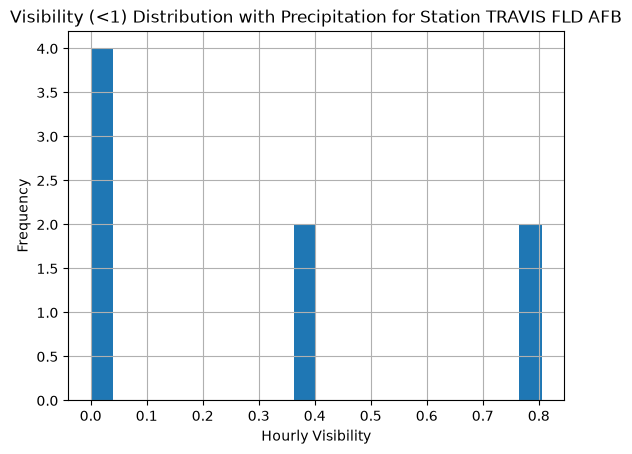

In [18]:
# Identify rows with visibility < 1
CV_precip_lowvis = CV_precip_rows[CV_precip_rows['HourlyVisibility'] < 1]
print("CV_precip_lowvis:", CV_precip_lowvis.shape)

# Plot histogram of HourlyVisibility for each station
for station in CV_precip_lowvis['STATION'].unique():
    CV_precip_lowvis[CV_precip_lowvis['STATION'] == station]['HourlyVisibility'].hist(bins=20)
    plt.xlabel('Hourly Visibility')
    plt.ylabel('Frequency')
    plt.title(f'Visibility (<1) Distribution with Precipitation for Station {station}')
    plt.show()

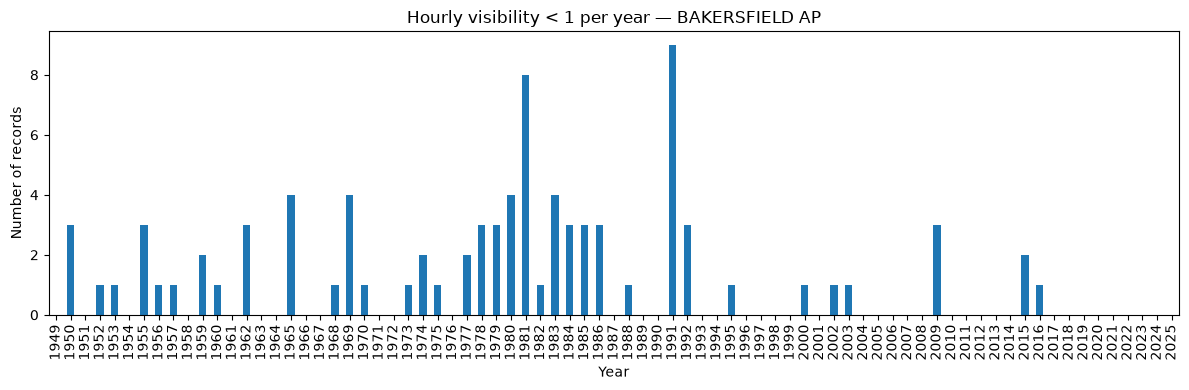

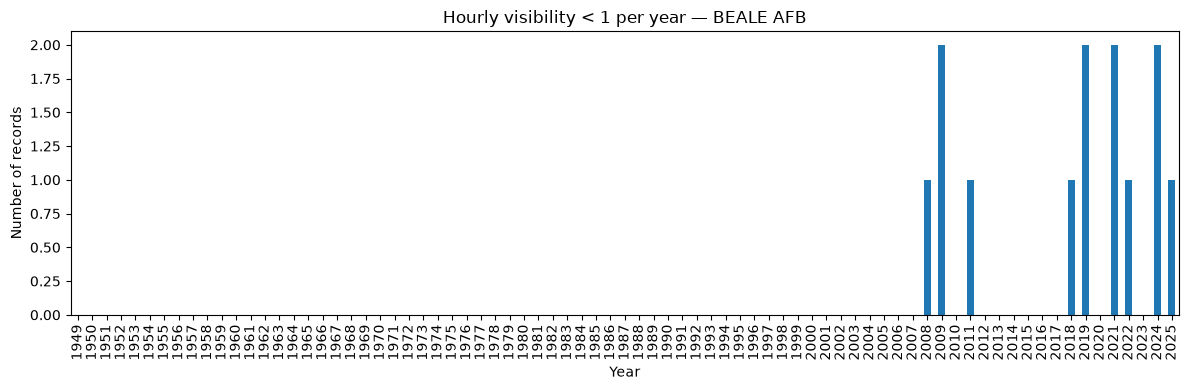

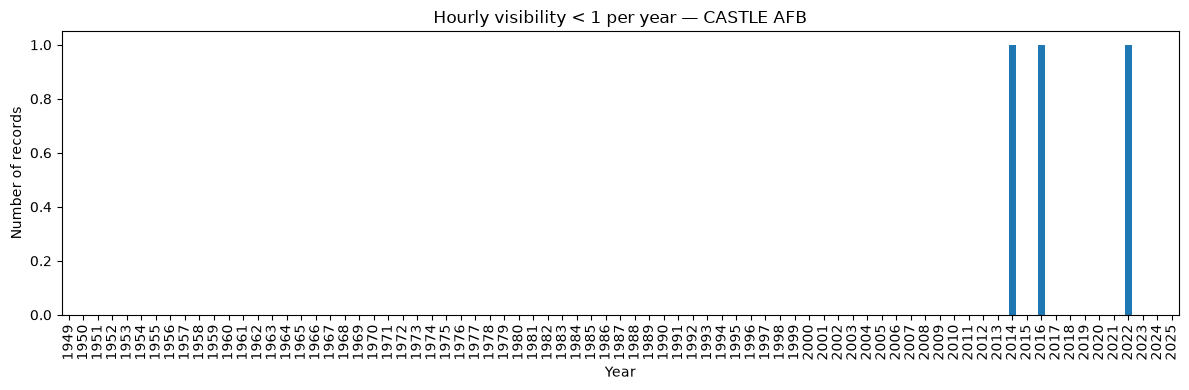

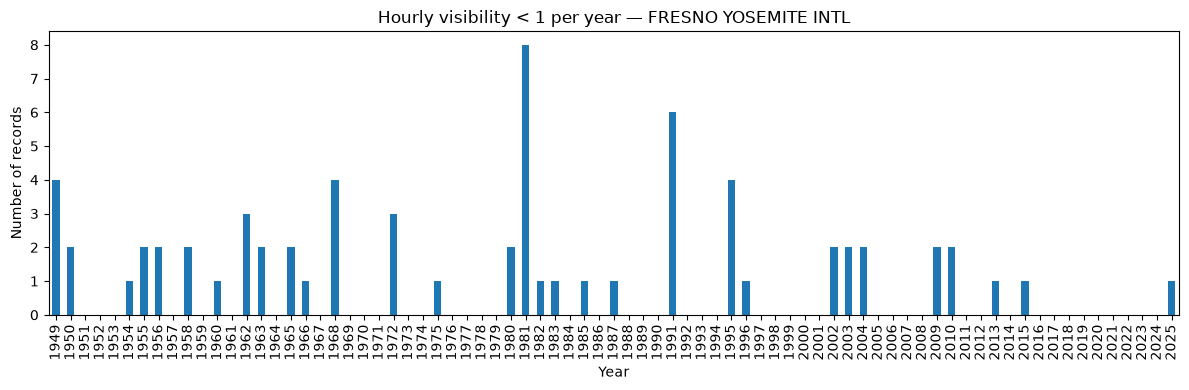

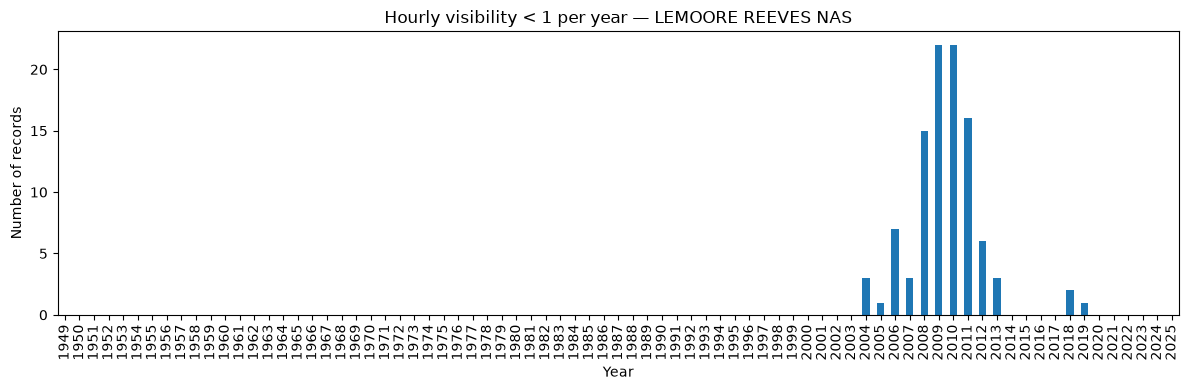

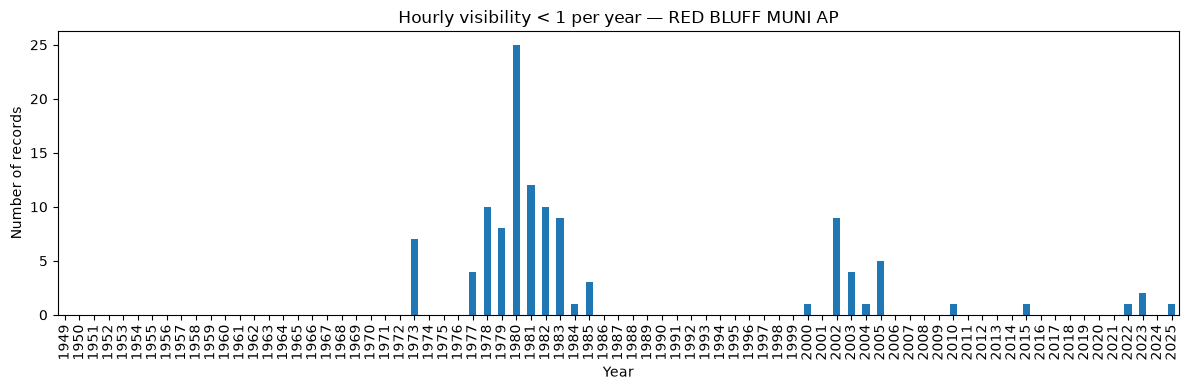

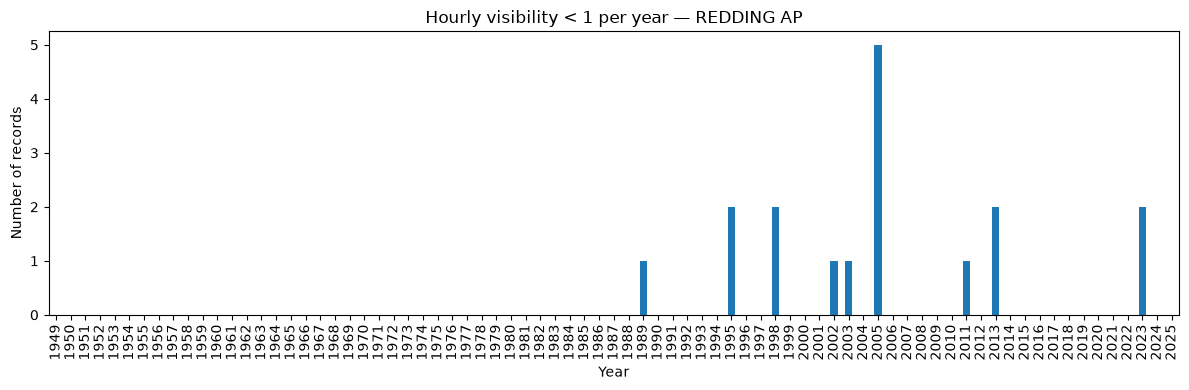

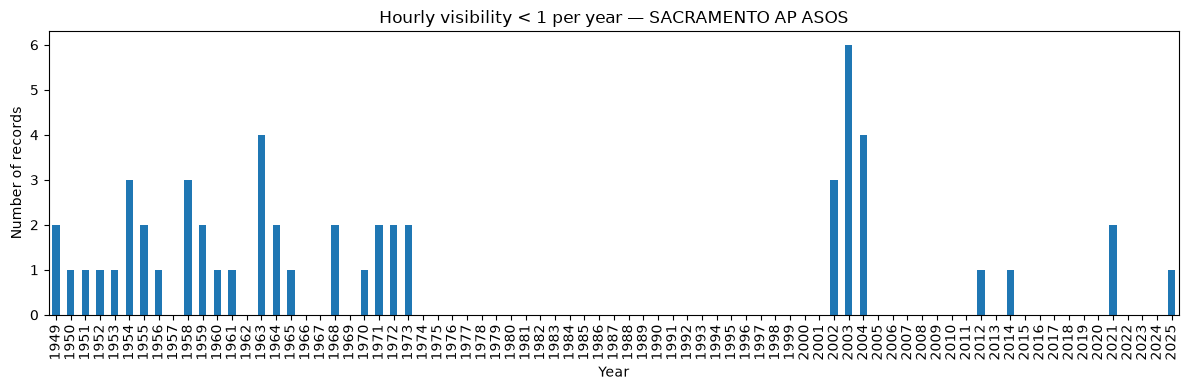

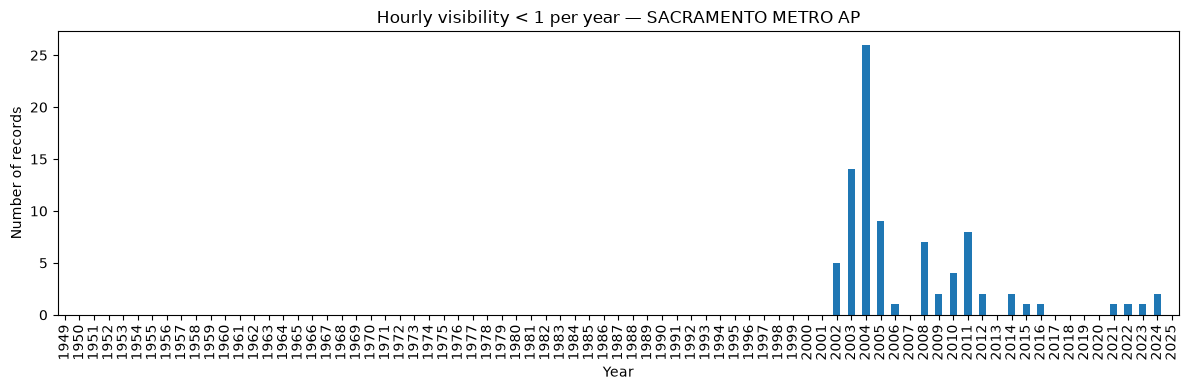

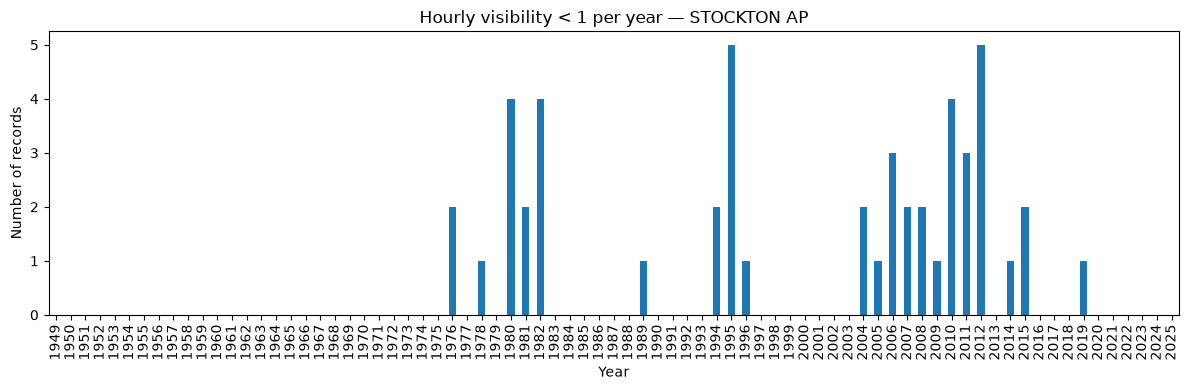

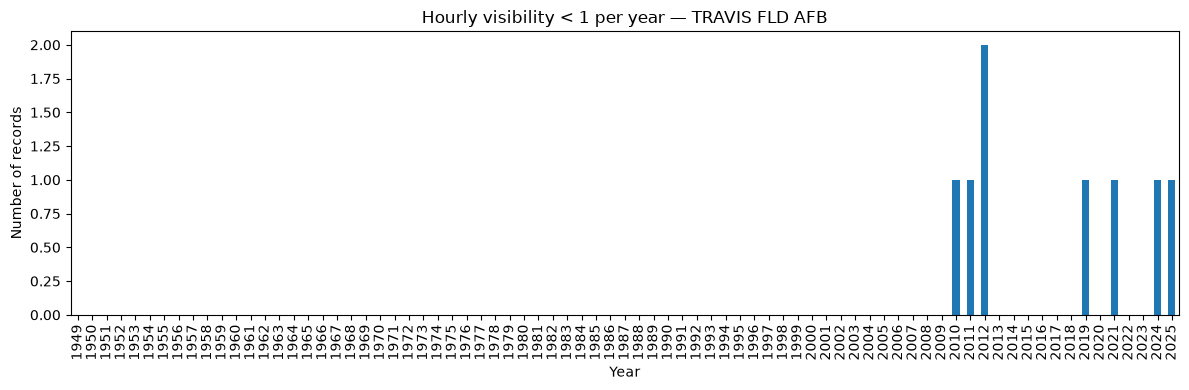

In [19]:
# Show missing years with empty bars in the annual counts plots
annual_counts = CV_precip_lowvis.groupby(['STATION', 'year']).size()

for station_name in CV_precip_lowvis['STATION'].unique():
    station_counts = annual_counts.loc[station_name].sort_index()
    all_years = range(CV_precip_lowvis['year'].min(), CV_precip_lowvis['year'].max() + 1)
    station_counts = station_counts.reindex(all_years, fill_value=0)   

    plt.figure(figsize=(12, 4))
    station_counts.plot(kind='bar')
    plt.xlabel('Year')
    plt.ylabel('Number of records')
    plt.title(f'Hourly visibility < 1 per year — {station_name}')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [20]:
precip = CV_precip_rows[['STATION', 'DATE', 'HourlyPrecipitation']].copy()
precip['DATE'] = pd.to_datetime(precip['DATE'])

low_vis = CV_vis_rows.loc[
    CV_vis_rows['HourlyVisibility'].lt(1),
    ['STATION', 'DATE', 'HourlyVisibility']
].copy()
low_vis['DATE'] = pd.to_datetime(low_vis['DATE'])

matches = []

for station_name, precip_station in precip.groupby('STATION'):
    vis_station = low_vis[low_vis['STATION'] == station_name].sort_values('DATE')
    vis_times = vis_station['DATE'].to_numpy()

    for row in precip_station.itertuples(index=False):
        start = np.searchsorted(vis_times, np.datetime64(row.DATE), side='left')
        end = np.searchsorted(
            vis_times,
            np.datetime64(row.DATE + pd.Timedelta(days=1)),
            side='right'
        )

        for vis_row in vis_station.iloc[start:end].itertuples(index=False):
            matches.append({
                'STATION': station_name,
                'precip_time': row.DATE,
                'HourlyPrecipitation': row.HourlyPrecipitation,
                'low_visibility_time': vis_row.DATE,
                'HourlyVisibility': vis_row.HourlyVisibility
            })

overlapping_times = pd.DataFrame(matches)
overlapping_times

,STATION,precip_time,HourlyPrecipitation,low_visibility_time,HourlyVisibility
0,BAKERSFIELD AP,1948-12-03 15:00:00,1.5,1948-12-04 05:00:00,0.400
1,BAKERSFIELD AP,1948-12-03 16:00:00,0.8,1948-12-04 05:00:00,0.400
2,BAKERSFIELD AP,1948-12-03 21:00:00,0.3,1948-12-04 05:00:00,0.400
3,BAKERSFIELD AP,1948-12-27 09:00:00,1.8,1948-12-28 05:00:00,0.200
4,BAKERSFIELD AP,1948-12-27 09:00:00,1.8,1948-12-28 08:00:00,0.100
...,...,...,...,...,...
30875,TRAVIS FLD AFB,2025-12-22 10:55:00,1.7,2025-12-23 07:05:00,0.402
30876,TRAVIS FLD AFB,2025-12-22 10:55:00,1.7,2025-12-23 08:25:00,0.000
30877,TRAVIS FLD AFB,2025-12-22 10:55:00,1.7,2025-12-23 09:15:00,0.000
30878,TRAVIS FLD AFB,2025-12-22 10:55:00,1.7,2025-12-23 10:55:00,0.201


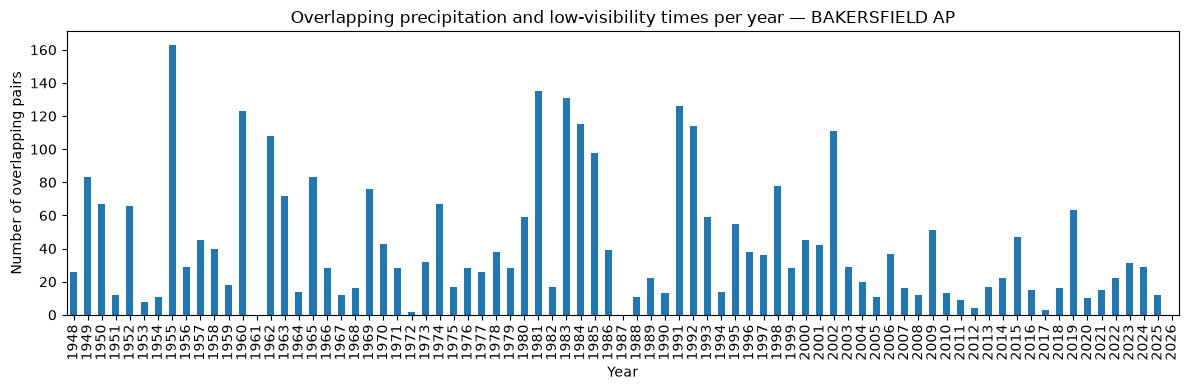

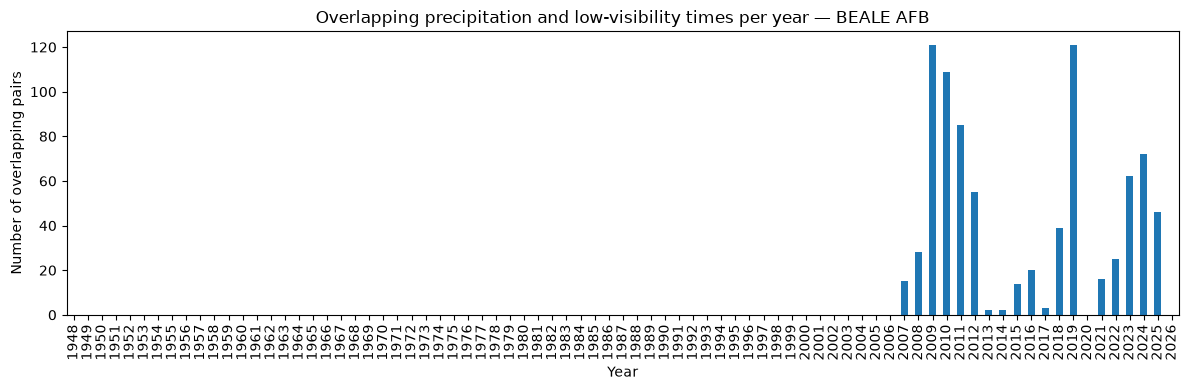

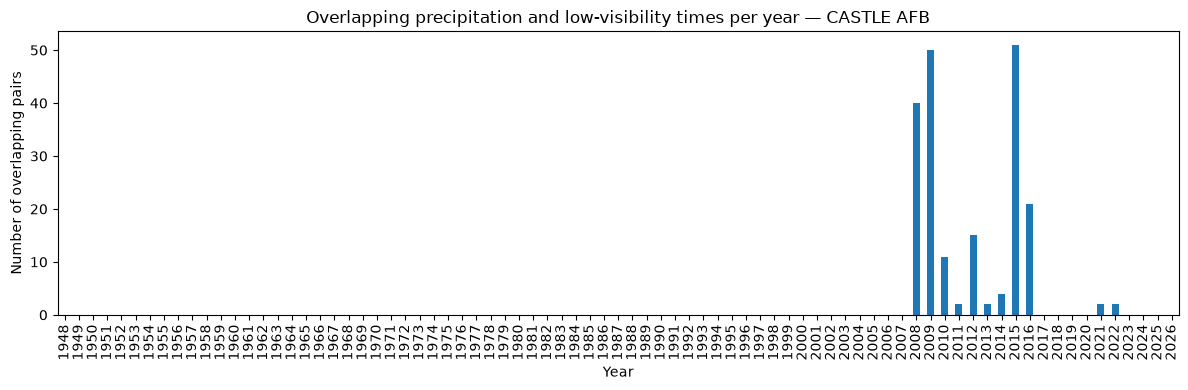

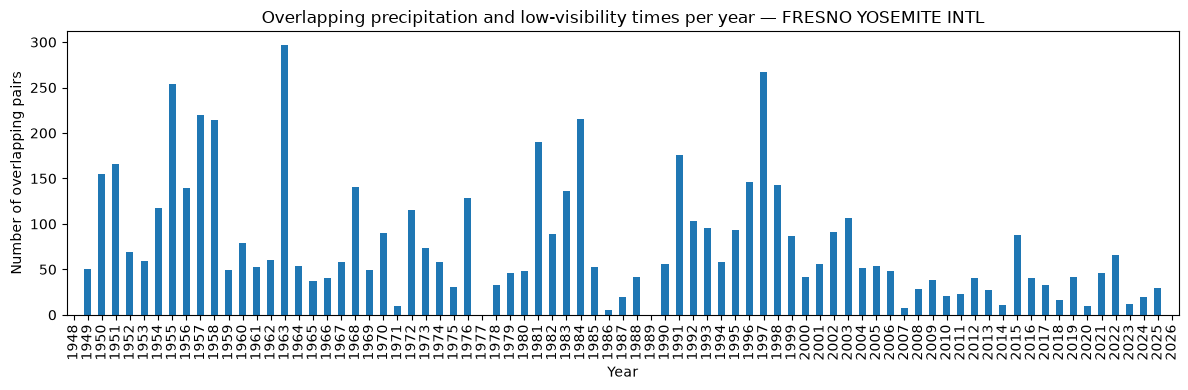

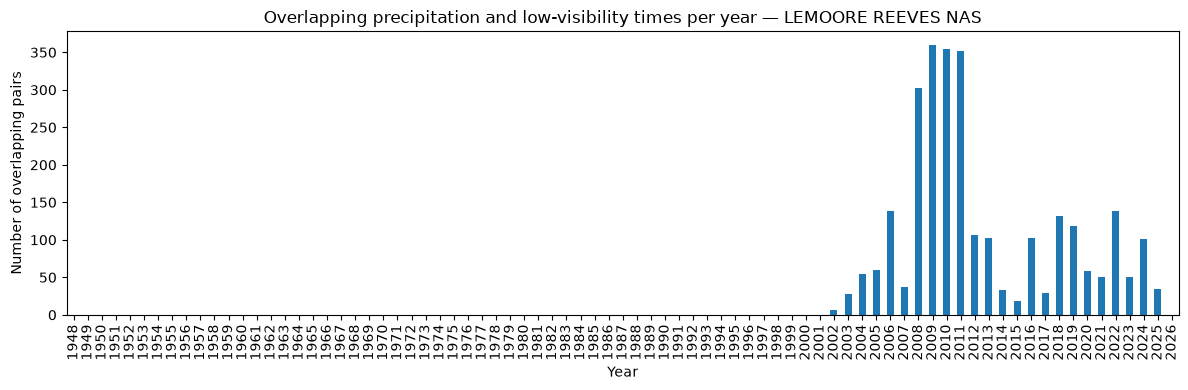

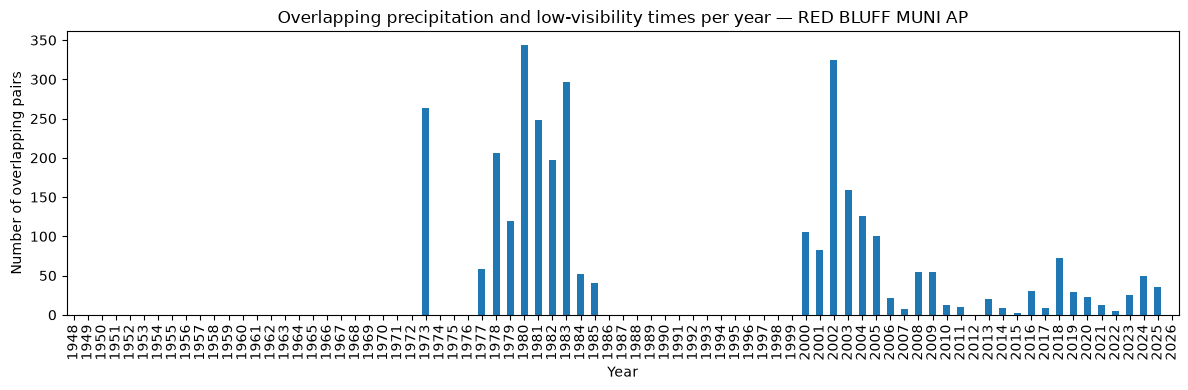

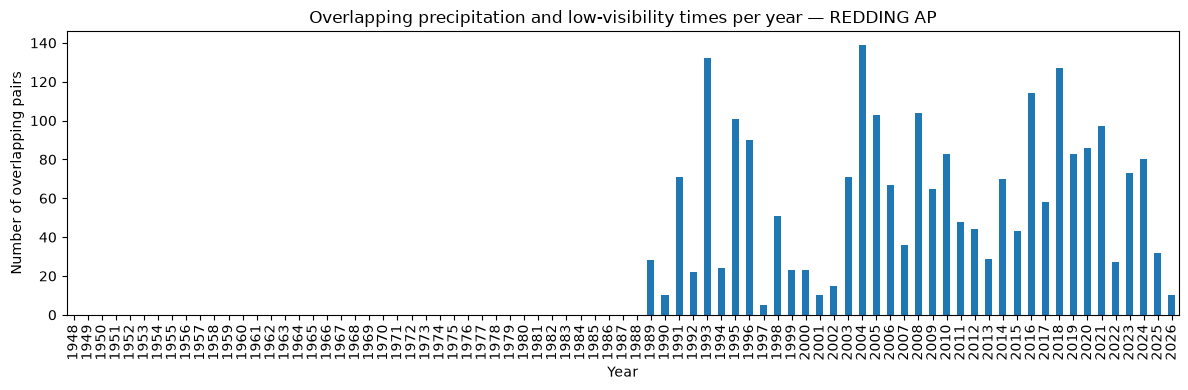

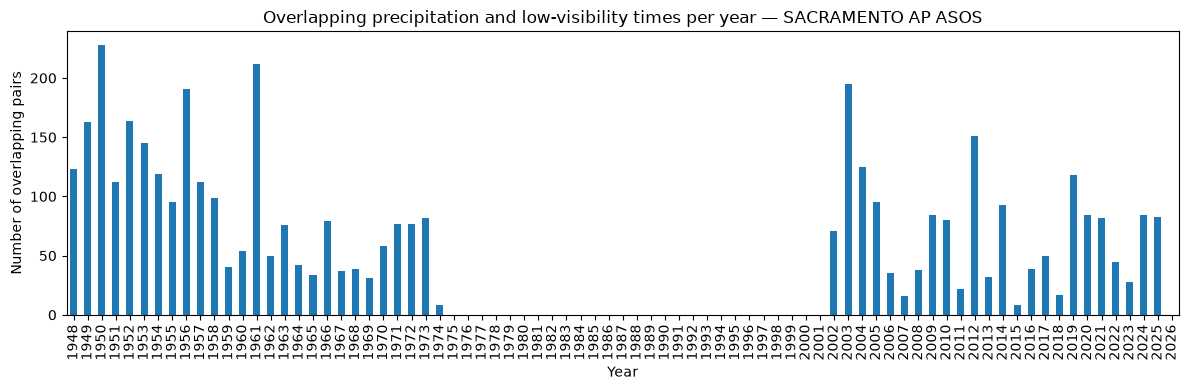

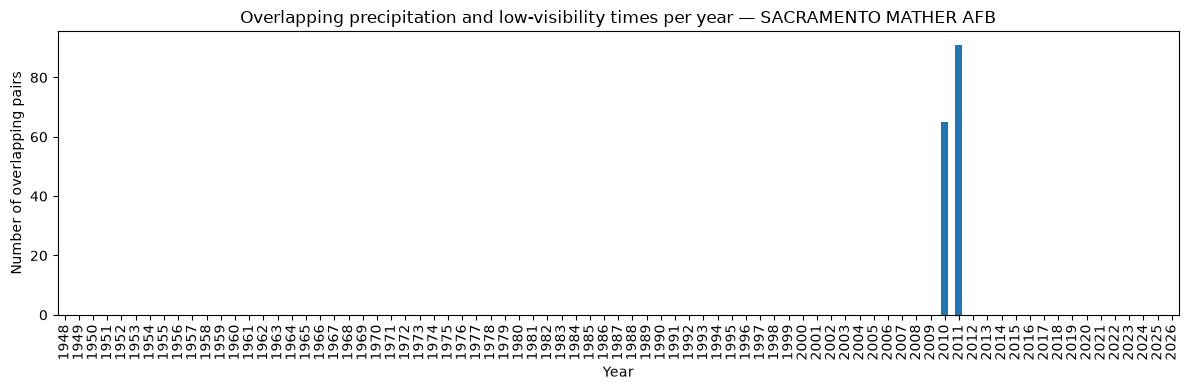

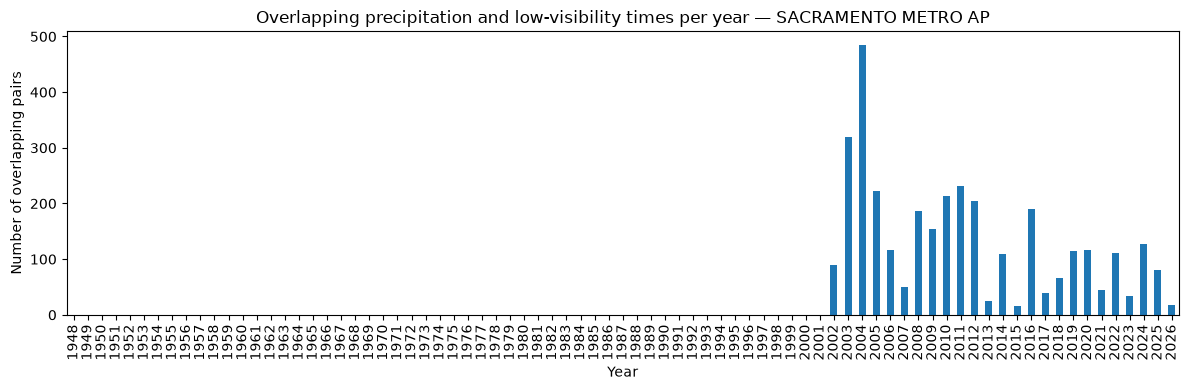

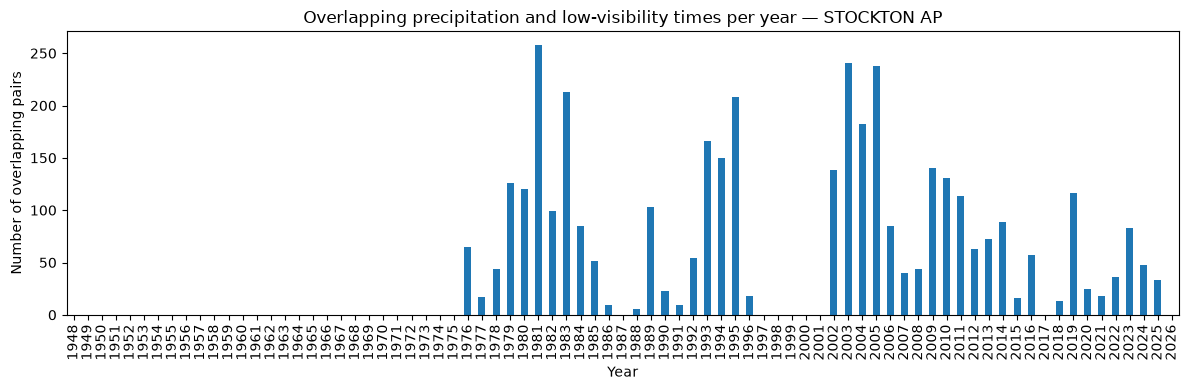

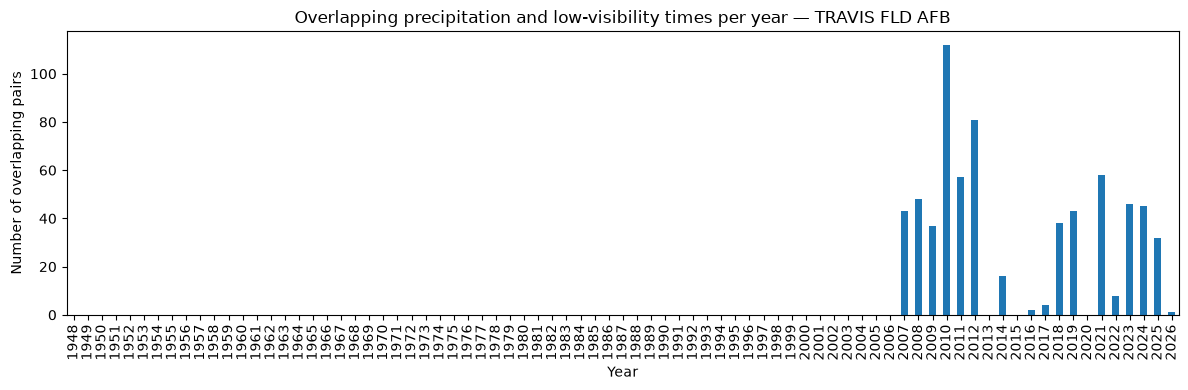

In [21]:
overlap_by_year = overlapping_times.copy()
overlap_by_year['year'] = pd.to_datetime(
    overlap_by_year['low_visibility_time']
).dt.year

annual_overlap_counts = overlap_by_year.groupby(['STATION', 'year']).size()

all_years = range(
    overlap_by_year['year'].min(),
    overlap_by_year['year'].max() + 1
)

for station_name in overlap_by_year['STATION'].unique():
    counts = (
        annual_overlap_counts
        .loc[station_name]
        .reindex(all_years, fill_value=0)
    )

    plt.figure(figsize=(12, 4))
    counts.plot(kind='bar')
    plt.xlabel('Year')
    plt.ylabel('Number of overlapping pairs')
    plt.title(f'Overlapping precipitation and low-visibility times per year — {station_name}')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [22]:
# Create station-day precipitation and visibility indicators
daily_obs = CV_rows[['STATION', 'DATE', 'HourlyPrecipitation', 'HourlyVisibility']].copy()
daily_obs['day'] = pd.to_datetime(daily_obs['DATE']).dt.normalize()

daily_obs['precip_valid'] = daily_obs['HourlyPrecipitation'].notna()
daily_obs['precip_event'] = daily_obs['HourlyPrecipitation'].ge(0.03)
daily_obs['vis_valid'] = daily_obs['HourlyVisibility'].notna()
daily_obs['lowvis_event'] = daily_obs['HourlyVisibility'].lt(1)

daily = (
    daily_obs.groupby(['STATION', 'day'])
    .agg(
        precip_obs=('precip_valid', 'sum'),
        precip_any=('precip_event', 'max'),
        vis_obs=('vis_valid', 'sum'),
        lowvis_any=('lowvis_event', 'max')
    )
    .reset_index()
)

# Align each day's precipitation with visibility observed the following day
next_day_vis = daily[['STATION', 'day', 'vis_obs', 'lowvis_any']].copy()
next_day_vis['day'] -= pd.Timedelta(days=1)
next_day_vis = next_day_vis.rename(columns={
    'vis_obs': 'next_day_vis_obs',
    'lowvis_any': 'lowvis_next'
})

records = daily[['STATION', 'day', 'precip_obs', 'precip_any']].merge(
    next_day_vis, on=['STATION', 'day'], how='left'
)

# Keep days with measured precipitation and measured visibility the next day
records = records[
    records['precip_obs'].gt(0) & records['next_day_vis_obs'].gt(0)
].copy()

records['precip_any'] = records['precip_any'].astype(int)
records['lowvis_next'] = records['lowvis_next'].astype(int)
records['year'] = records['day'].dt.year

# Overall station-level binary correlation (phi / Pearson correlation)
results = []

for station, group in records.groupby('STATION'):
    if group['precip_any'].nunique() == 2 and group['lowvis_next'].nunique() == 2:
        test = stats.pearsonr(group['precip_any'], group['lowvis_next'])
        correlation, p_value = test.statistic, test.pvalue
    else:
        correlation, p_value = np.nan, np.nan

    # Test whether the precipitation–low-visibility association changes over time
    group = group.copy()
    group['year_decade'] = (group['year'] - group['year'].mean()) / 10

    try:
        model = smf.glm(
            'lowvis_next ~ precip_any * year_decade',
            data=group,
            family=sm.families.Binomial()
        ).fit()

        interaction = 'precip_any:year_decade'
        interaction_or = np.exp(model.params[interaction])
        interaction_p = model.pvalues[interaction]
    except Exception:
        interaction_or, interaction_p = np.nan, np.nan

    results.append({
        'STATION': station,
        'daily_phi_correlation': correlation,
        'correlation_p_value': p_value,
        'change_in_precip_association_OR_per_decade': interaction_or,
        'trend_interaction_p_value': interaction_p,
        'eligible_station_days': len(group)
    })

station_results = pd.DataFrame(results)
station_results

,STATION,daily_phi_correlation,correlation_p_value,change_in_precip_association_OR_per_decade,trend_interaction_p_value,eligible_station_days
0,BAKERSFIELD AP,0.058400,1.083082e-27,1.039322,0.179145,34815
1,BEALE AFB,0.049966,3.169586e-14,1.703249,0.003438,23056
2,CASTLE AFB,0.019623,1.989358e-03,1.936408,0.184948,24824
3,FRESNO YOSEMITE INTL,0.058005,1.828145e-23,1.011756,0.640968,29567
4,LEMOORE REEVES NAS,0.078383,2.584988e-33,0.866213,0.245882,23471
5,RED BLUFF MUNI AP,0.043585,5.441262e-14,0.886742,0.018872,29750
6,REDDING AP,0.107545,1.385852e-51,1.077291,0.327281,19629
7,SACRAMENTO AP ASOS,0.042051,1.260511e-14,1.069854,0.001731,33588
8,SACRAMENTO MATHER AFB,0.010700,7.603668e-02,0.330954,0.749418,27495
9,SACRAMENTO MCCLELLAN AFB,-0.003741,5.405021e-01,0.016346,0.999020,26767


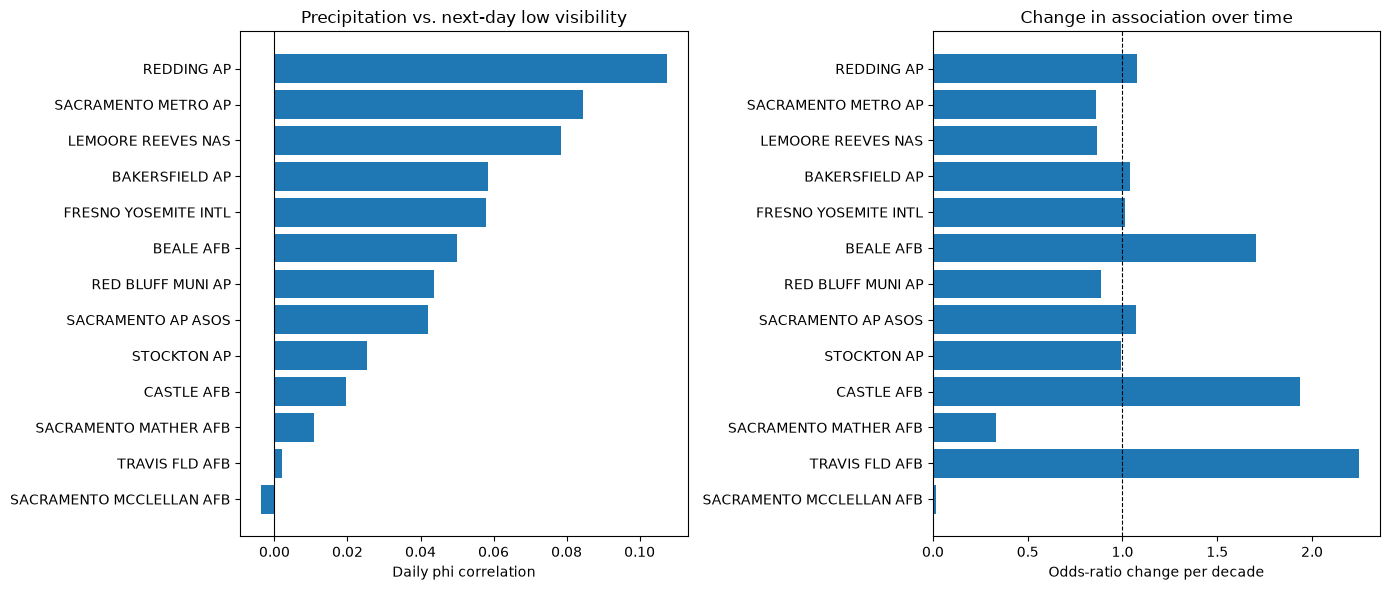

In [23]:
# Compare station-level precipitation/visibility associations
plot_data = station_results.sort_values('daily_phi_correlation')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(plot_data['STATION'], plot_data['daily_phi_correlation'])
axes[0].axvline(0, color='black', linewidth=0.8)
# daily phi correlation shows us
# the strength and direction of the association between precipitation and next-day low visibility
axes[0].set_xlabel('Daily phi correlation')
# higher values (closer to 1) indicate a stronger positive association
# lower values (closer to -1) indicate a negative association
axes[0].set_title('Precipitation vs. next-day low visibility')

axes[1].barh(
    plot_data['STATION'],
    plot_data['change_in_precip_association_OR_per_decade']
)
axes[1].axvline(1, color='black', linestyle='--', linewidth=0.8)
# odds-ratio of change per decade means no change if equal to 1
axes[1].set_xlabel('Odds-ratio change per decade')
# change in association over time means the odds of low visibility following precipitation
# are increasing or decreasing over decades
axes[1].set_title('Change in association over time')

plt.tight_layout()
plt.show()

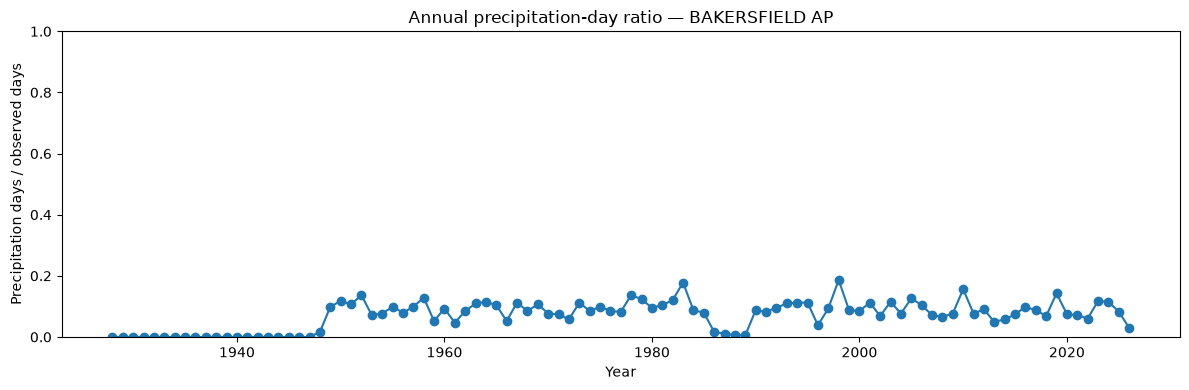

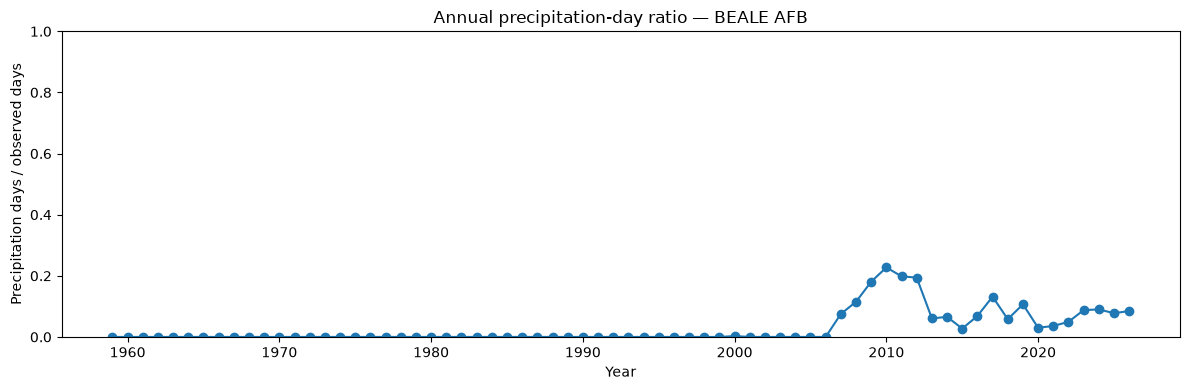

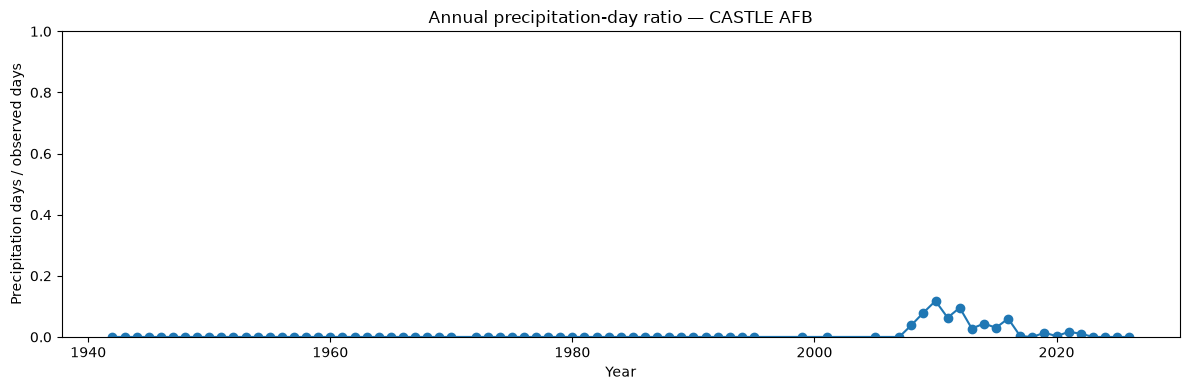

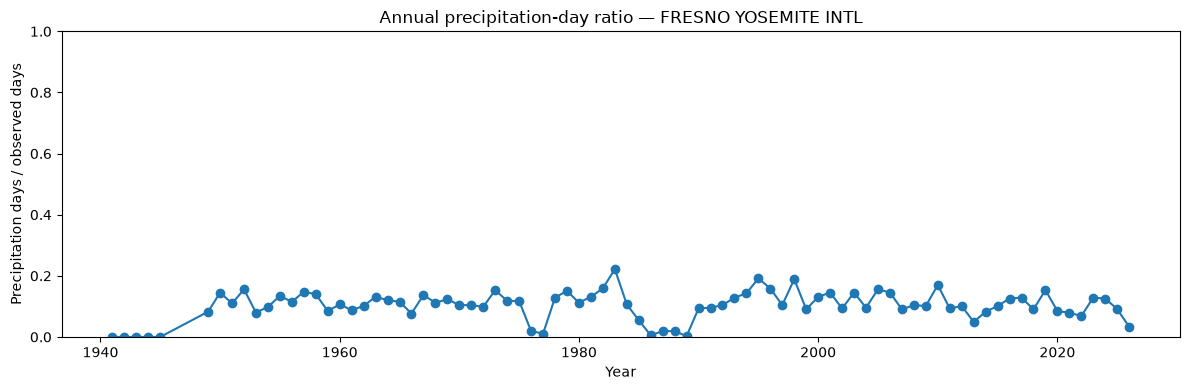

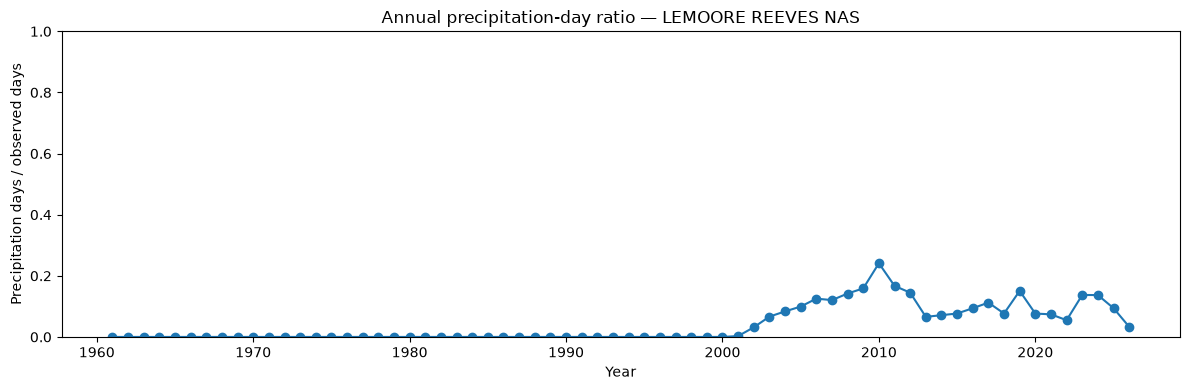

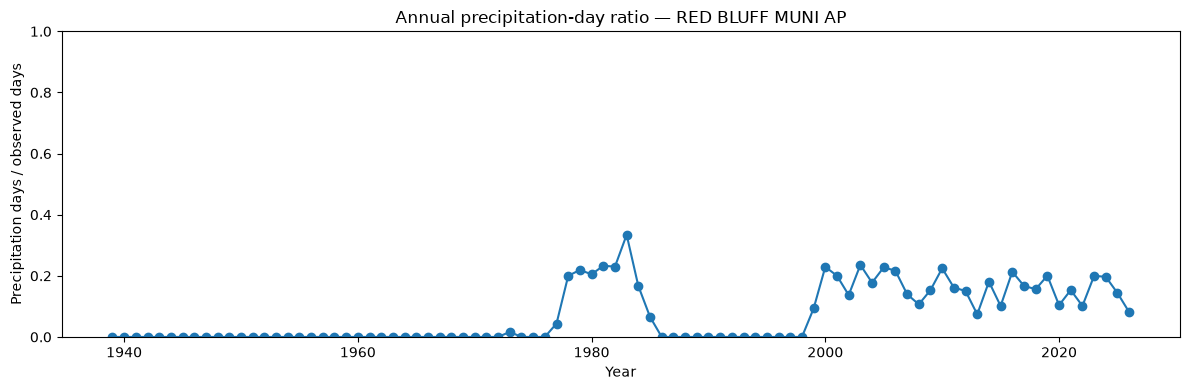

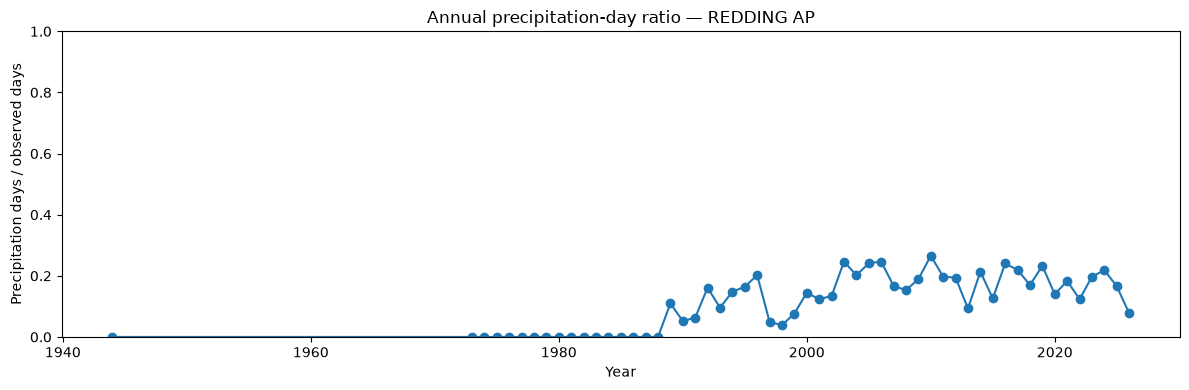

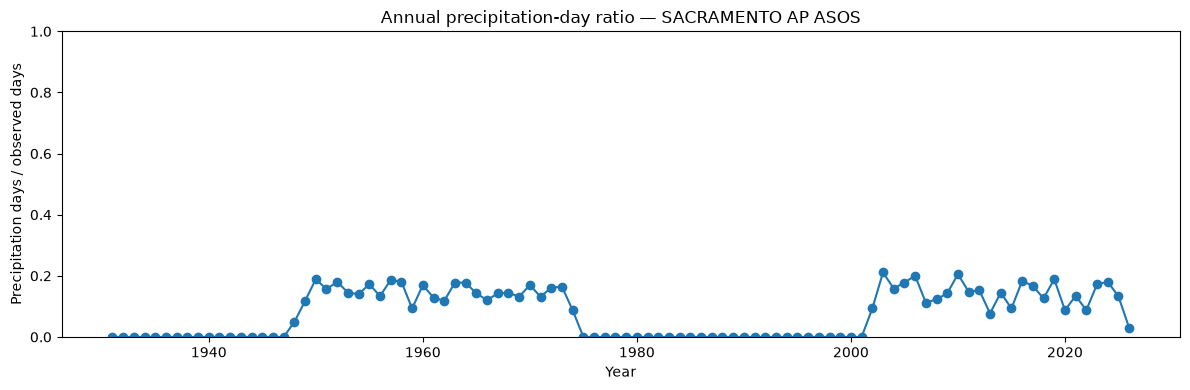

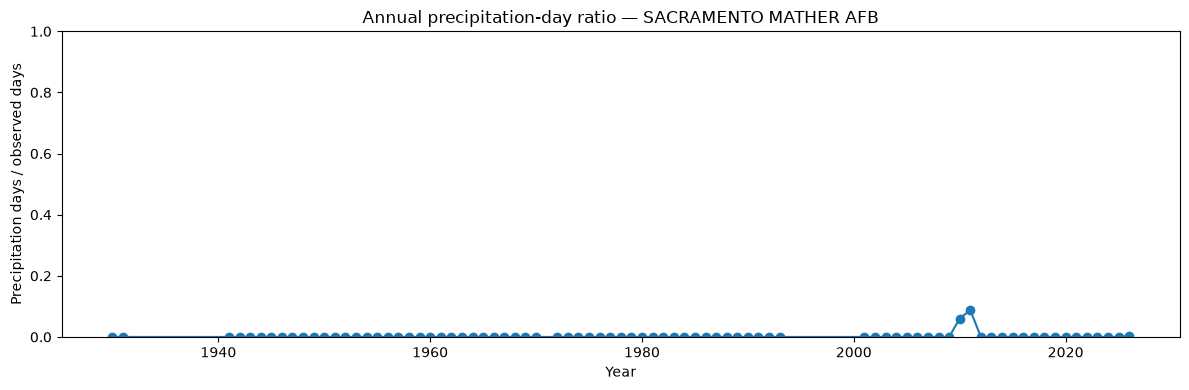

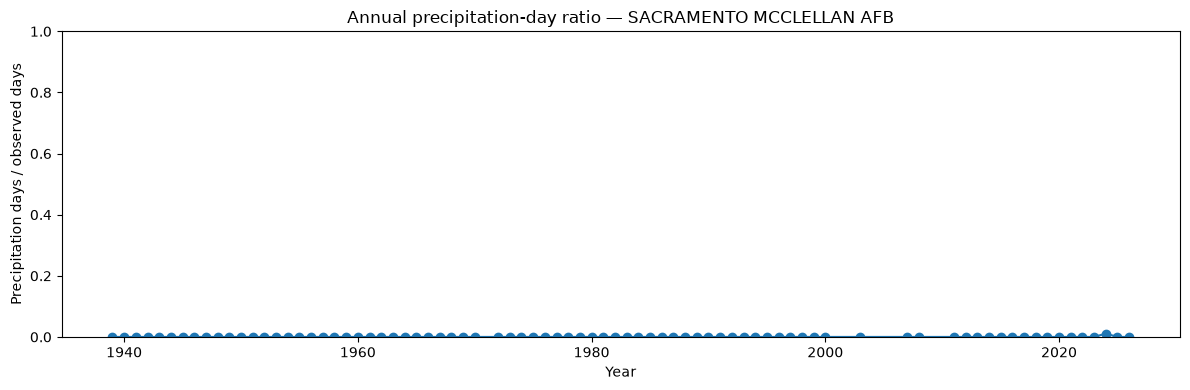

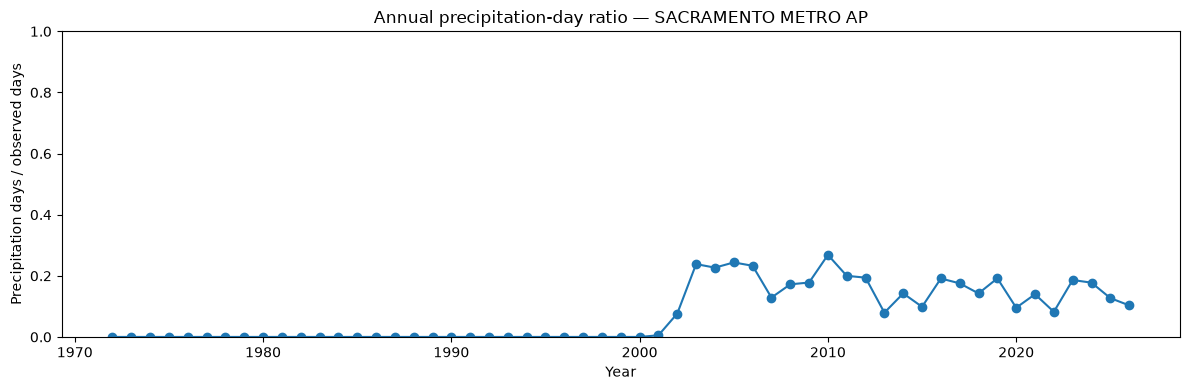

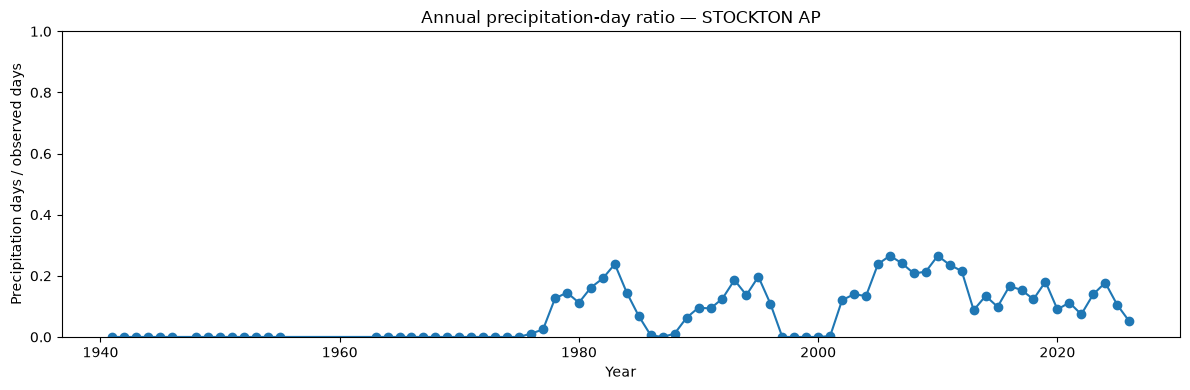

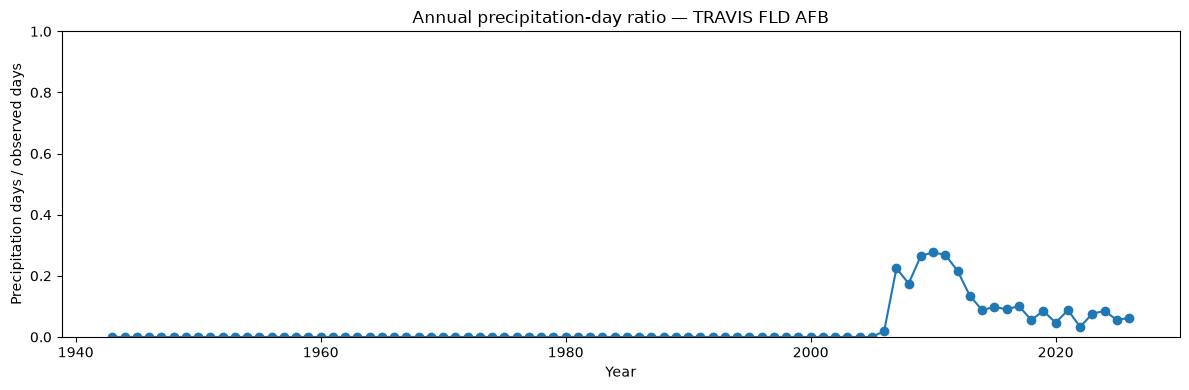

In [24]:
# Count unique station-days in each dataset
cv_days = CV_rows[['STATION', 'year', 'month', 'day']].drop_duplicates()
precip_days = CV_precip_rows[['STATION', 'year', 'month', 'day']].drop_duplicates()

cv_annual_days = cv_days.groupby(['STATION', 'year']).size().rename('cv_days')
precip_annual_days = precip_days.groupby(['STATION', 'year']).size().rename('precip_days')

# Include years with no precipitation days and calculate the ratio
annual_day_ratio = cv_annual_days.to_frame().join(precip_annual_days)
annual_day_ratio['precip_days'] = annual_day_ratio['precip_days'].fillna(0)
annual_day_ratio['day_ratio'] = annual_day_ratio['precip_days'] / annual_day_ratio['cv_days']

# Plot the ratio by year for each station
for station_name, station_data in annual_day_ratio.groupby(level='STATION'):
    station_data = station_data.droplevel('STATION').sort_index()

    plt.figure(figsize=(12, 4))
    plt.plot(station_data.index, station_data['day_ratio'], marker='o')
    plt.xlabel('Year')
    plt.ylabel('Precipitation days / observed days')
    plt.title(f'Annual precipitation-day ratio — {station_name}')
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [25]:
from statsmodels.stats.multitest import multipletests

trend_data = annual_day_ratio.reset_index()

# Exclude the latest year because it may be incomplete
latest_year = trend_data['year'].max()
trend_data = trend_data[trend_data['year'] < latest_year].copy()

trend_results = []

for station, group in trend_data.groupby('STATION'):
    group = group.dropna(subset=['cv_days', 'precip_days']).copy()
    group = group[group['cv_days'] > 0]

    # Scale time so the coefficient represents a change per decade
    group['year_decade'] = (group['year'] - group['year'].mean()) / 10
    proportion = group['precip_days'] / group['cv_days']

    try:
        X = sm.add_constant(group['year_decade'])
        model = sm.GLM(
            proportion,
            X,
            family=sm.families.Binomial(),
            freq_weights=group['cv_days']
        ).fit()

        beta = model.params['year_decade']
        ci_low, ci_high = model.conf_int().loc['year_decade']

        trend_results.append({
            'STATION': station,
            'odds_ratio_per_decade': np.exp(beta),
            'ci_low': np.exp(ci_low),
            'ci_high': np.exp(ci_high),
            'p_value': model.pvalues['year_decade'],
            'years': len(group)
        })
    except Exception as exc:
        print(f"Could not fit trend for {station}: {exc}")

trend_results = pd.DataFrame(trend_results)

if not trend_results.empty:
    trend_results['fdr_p_value'] = multipletests(
        trend_results['p_value'], method='fdr_bh'
    )[1]
    trend_results['significant_fdr'] = trend_results['fdr_p_value'] < 0.05
    trend_results['direction'] = np.where(
        trend_results['odds_ratio_per_decade'] > 1, 'increasing', 'decreasing'
    )
    display(trend_results.sort_values('fdr_p_value'))

,STATION,odds_ratio_per_decade,ci_low,ci_high,p_value,years,fdr_p_value,significant_fdr,direction
5,RED BLUFF MUNI AP,1.532566,1.498693,1.567205e+00,8.669273e-307,87,1.127005e-305,True,increasing
11,STOCKTON AP,1.464572,1.430547,1.499407e+00,4.048492e-222,77,2.307443e-221,True,increasing
10,SACRAMENTO METRO AP,2.192931,2.089346,2.301652e+00,5.324869e-222,54,2.307443e-221,True,increasing
6,REDDING AP,1.700413,1.643391,1.759413e+00,2.269314e-204,54,7.375272e-204,True,increasing
12,TRAVIS FLD AFB,2.326343,2.197258,2.463012e+00,9.616447e-185,83,2.500276e-184,True,increasing
4,LEMOORE REEVES NAS,2.356067,2.221708,2.498552e+00,5.653793e-180,65,1.224988e-179,True,increasing
1,BEALE AFB,2.468141,2.296699,2.652381e+00,1.380063e-133,67,2.562973e-133,True,increasing
0,BAKERSFIELD AP,1.144137,1.127164,1.161365e+00,8.830308e-70,98,1.434925e-69,True,increasing
7,SACRAMENTO AP ASOS,1.115665,1.099332,1.132241e+00,6.256534e-48,95,9.037216e-48,True,increasing
2,CASTLE AFB,2.016003,1.832647,2.217703e+00,4.414495e-47,75,5.738843e-47,True,increasing


In [26]:
trend_data_since_1980 = annual_day_ratio.reset_index()
latest_year_since_1980 = trend_data_since_1980['year'].max()

trend_data_since_1980 = trend_data_since_1980[
    (trend_data_since_1980['year'] >= 1980) &
    (trend_data_since_1980['year'] < latest_year_since_1980)
].copy()

trend_results_since_1980 = []

for station, group in trend_data_since_1980.groupby('STATION'):
    group = group.dropna(subset=['cv_days', 'precip_days']).copy()
    group = group[group['cv_days'] > 0]

    group['year_decade'] = (group['year'] - group['year'].mean()) / 10
    proportion = group['precip_days'] / group['cv_days']

    try:
        X = sm.add_constant(group['year_decade'])
        model = sm.GLM(
            proportion,
            X,
            family=sm.families.Binomial(),
            freq_weights=group['cv_days']
        ).fit()

        beta = model.params['year_decade']
        ci_low, ci_high = model.conf_int().loc['year_decade']

        trend_results_since_1980.append({
            'STATION': station,
            'odds_ratio_per_decade': np.exp(beta),
            'ci_low': np.exp(ci_low),
            'ci_high': np.exp(ci_high),
            'p_value': model.pvalues['year_decade'],
            'years': len(group)
        })
    except Exception as exc:
        print(f"Could not fit trend for {station}: {exc}")

trend_results_since_1980 = pd.DataFrame(trend_results_since_1980)

if not trend_results_since_1980.empty:
    trend_results_since_1980['fdr_p_value'] = multipletests(
        trend_results_since_1980['p_value'], method='fdr_bh'
    )[1]
    trend_results_since_1980['significant_fdr'] = (
        trend_results_since_1980['fdr_p_value'] < 0.05
    )
    trend_results_since_1980['direction'] = np.where(
        trend_results_since_1980['odds_ratio_per_decade'] > 1,
        'increasing',
        'decreasing'
    )
    display(trend_results_since_1980.sort_values('fdr_p_value'))

,STATION,odds_ratio_per_decade,ci_low,ci_high,p_value,years,fdr_p_value,significant_fdr,direction
10,SACRAMENTO METRO AP,2.087342,1.983847,2.196237e+00,5.914444e-177,46,7.688777e-176,True,increasing
7,SACRAMENTO AP ASOS,2.182153,2.064412,2.306610e+00,2.351301e-167,46,1.528346e-166,True,increasing
4,LEMOORE REEVES NAS,2.184267,2.048461,2.329075e+00,8.991492e-126,46,3.896313e-125,True,increasing
6,REDDING AP,1.555280,1.498899,1.613781e+00,1.550492e-121,46,5.039098e-121,True,increasing
12,TRAVIS FLD AFB,2.124466,1.991963,2.265784e+00,2.191224e-116,46,5.697183e-116,True,increasing
1,BEALE AFB,2.319261,2.145748,2.506805e+00,8.799042e-100,46,1.906459e-99,True,increasing
2,CASTLE AFB,1.691516,1.509982,1.894876e+00,1.142269e-19,38,2.121356e-19,True,increasing
5,RED BLUFF MUNI AP,1.154661,1.114408,1.196367e+00,1.967220e-15,46,3.196733e-15,True,increasing
11,STOCKTON AP,1.122150,1.084239,1.161386e+00,4.951270e-11,46,7.151835e-11,True,increasing
8,SACRAMENTO MATHER AFB,1.461681,1.176407,1.816132e+00,6.113236e-04,39,7.947207e-04,True,increasing


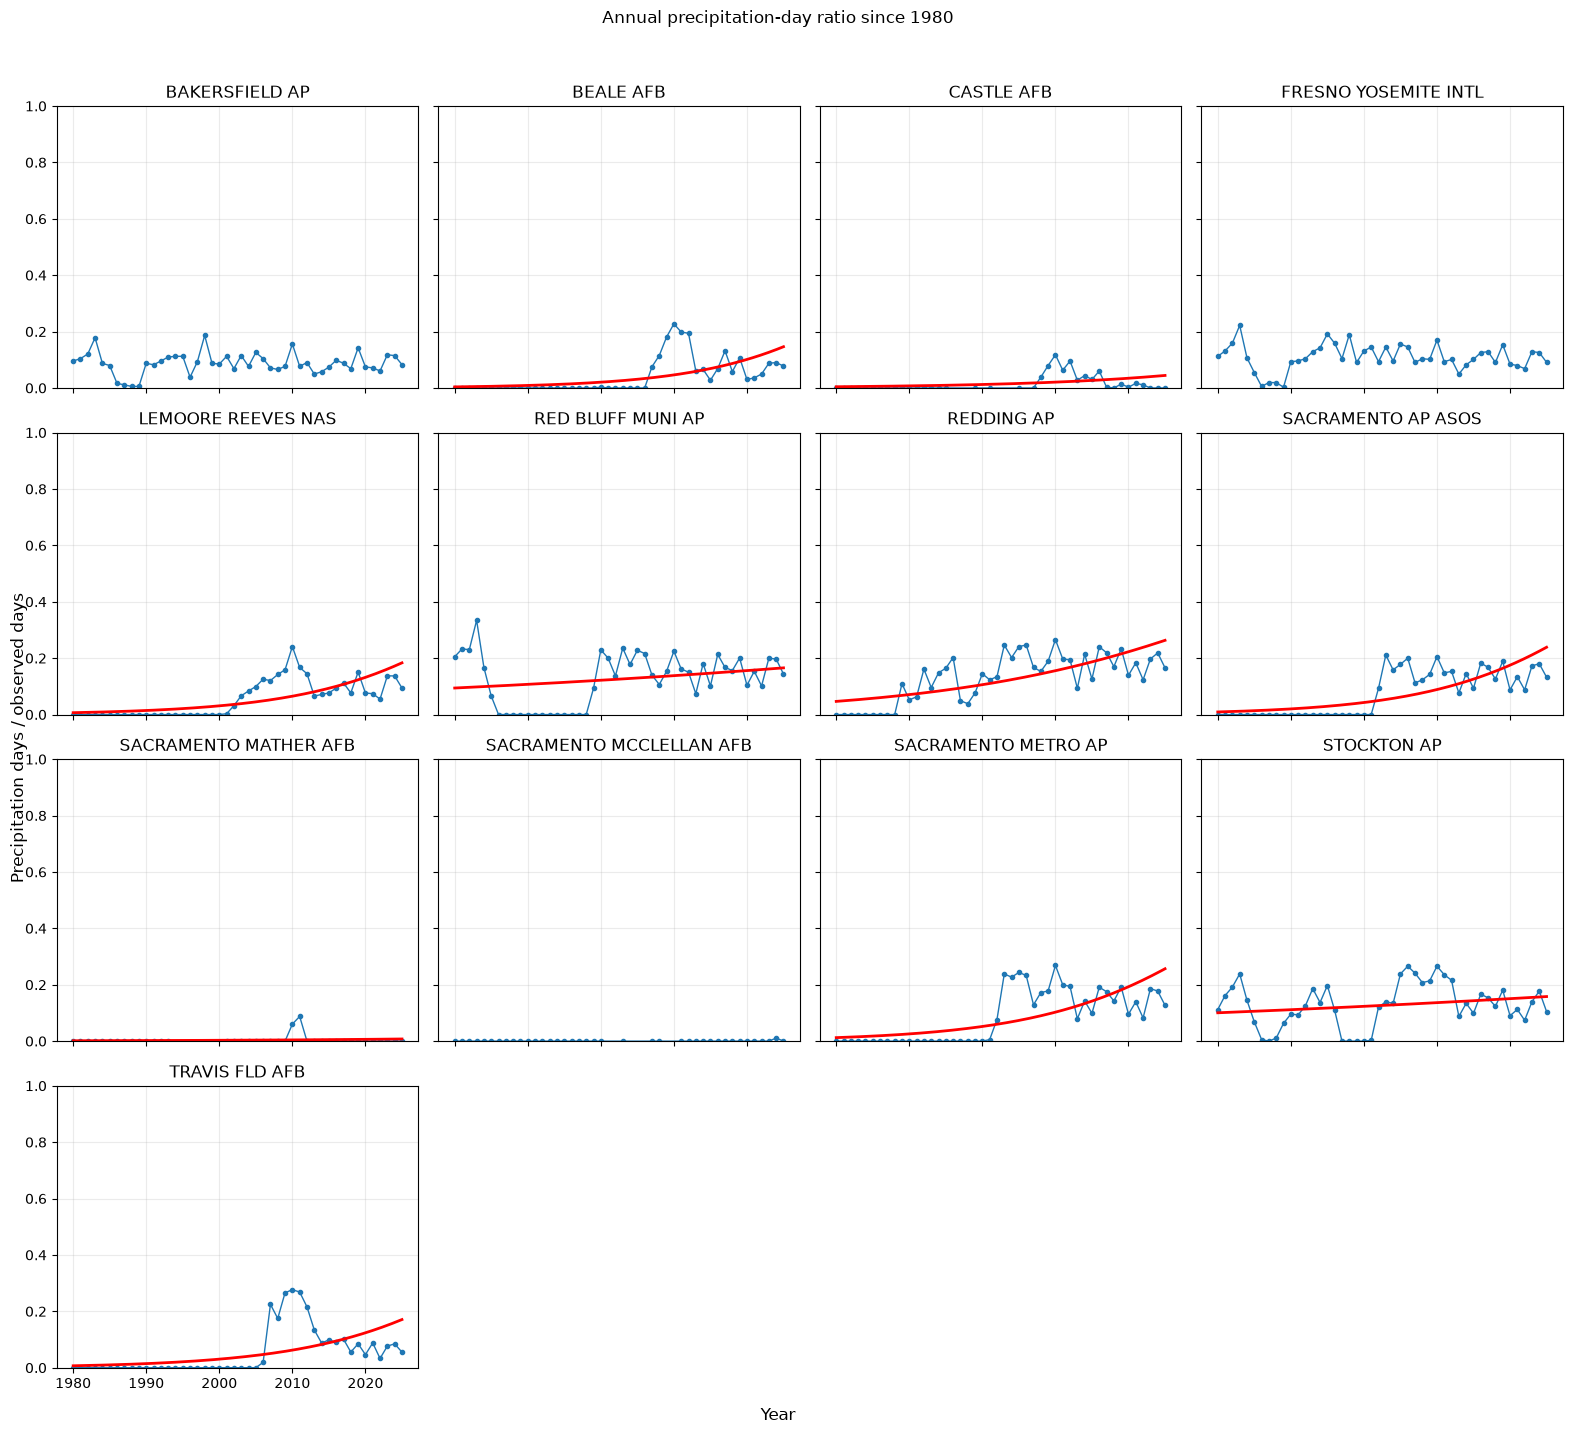

In [27]:
stations = trend_data_since_1980['STATION'].unique()
ncols = 4
nrows = int(np.ceil(len(stations) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(16, 3.5 * nrows),
    sharex=True, sharey=True
)
axes = np.asarray(axes).ravel()

significant_stations = set(
    trend_results_since_1980.loc[
        trend_results_since_1980['significant_fdr'], 'STATION'
    ]
)

for ax, station_name in zip(axes, stations):
    station_data = (
        trend_data_since_1980[
            trend_data_since_1980['STATION'] == station_name
        ]
        .dropna(subset=['year', 'cv_days', 'precip_days'])
        .sort_values('year')
        .copy()
    )

    ax.plot(
        station_data['year'], station_data['day_ratio'],
        marker='o', markersize=3, linewidth=1, label='Observed'
    )

    if station_name in significant_stations:
        station_data['year_decade'] = (
            station_data['year'] - station_data['year'].mean()
        ) / 10
        X = sm.add_constant(station_data['year_decade'])

        model = sm.GLM(
            station_data['precip_days'] / station_data['cv_days'],
            X,
            family=sm.families.Binomial(),
            freq_weights=station_data['cv_days']
        ).fit()

        line_years = np.linspace(
            station_data['year'].min(), station_data['year'].max(), 200
        )
        line_x = pd.DataFrame({
            'const': 1.0,
            'year_decade': (line_years - station_data['year'].mean()) / 10
        })

        ax.plot(
            line_years, model.predict(line_x),
            color='red', linewidth=2, label='Significant trend (FDR < 0.05)'
        )

    ax.set_title(station_name)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

for ax in axes[len(stations):]:
    ax.set_visible(False)

fig.supxlabel('Year')
fig.supylabel('Precipitation days / observed days')
fig.suptitle('Annual precipitation-day ratio since 1980', y=1.02)
fig.tight_layout()
plt.show()